<div style="border:solid Chocolate 2px; padding: 40px">

<b>Привет!</b>

Меня зовут Евгений Головин, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом.

В ходе работы я оставил тебе комментарии <font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге станет еще лучше, если внести небольшие коррективы.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>


<b>На доработку🤔:</b>
 Решение на этом шаге требует существенной переработки и внесения правок. Напоминаю, что проект не может быть принят с первого раза, если ревью содержит комментарии, рекомендующие доработать шаги.
</div>

Увидев мой комментарий, не удаляй его, он будет очень полезен в случае повторной проверки работы :)

<div class="alert alert-info">
<b>А свой помечай вот так, чтобы я его не потерял ;)</b>
</div>

На мои комменатрии можно и нужно реагировать, только делать это стоит так, чтобы твои и мои комменты не смешались: выделяй свои цветами, сильно отличающимися от моих.

Увидев у тебя неточность, в первый раз я лишь укажу на ее наличие и дам тебе возможность самому найти и исправить ее. На реальной работе твой руководитель будет поступать также, и я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку!
</div>

# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [1]:
%pip install numpy pandas pyarrow matplotlib seaborn python-dotenv boto3 scikit-learn sentence-transformers ipywidgets mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 107.0 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 134.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 110.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 105.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━

In [ ]:
import hashlib
import html
import io
import os
import random
import re
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from dotenv import load_dotenv
from IPython.display import display
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

load_dotenv()

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(
    torch.cuda.is_available(),
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "",
)

True Tesla T4


In [3]:
S3_ENDPOINT = "https://storage.yandexcloud.net"
SOURCE_BUCKET = "s3-ds-source"

RAW_PRODUCTS_PATH = "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = "queries_synthetic_test.parquet"


def get_s3_client():
    return boto3.client(
        "s3",
        endpoint_url=S3_ENDPOINT,
        region_name="ru-central1",
        aws_access_key_id=os.environ["S3_ACCESS_KEY"],
        aws_secret_access_key=os.environ["S3_SECRET_KEY"],
    )


def downcast_numeric(df: pd.DataFrame) -> pd.DataFrame:
    int_cols = df.select_dtypes(include=["integer"]).columns
    for col in int_cols:
        df[col] = pd.to_numeric(df[col], downcast="integer")

    float_cols = df.select_dtypes(include=["float"]).columns
    for col in float_cols:
        df[col] = pd.to_numeric(df[col], downcast="float")

    return df


def read_parquet_s3(s3, key: str, bucket: str = SOURCE_BUCKET) -> pd.DataFrame:
    obj = s3.get_object(Bucket=bucket, Key=key)
    df = pd.read_parquet(io.BytesIO(obj["Body"].read()))
    df = downcast_numeric(df)
    print("-" * 70)
    print(key, df.shape)
    display(df.head())
    display(df.describe(include="all"))
    df.info()
    print("Количество полных дубликатов строк:", df.duplicated().sum())
    return df


s3 = get_s3_client()

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очень аккуратная «шапка» проекта. Ключи к S3 берутся из `.env` и не светятся в тетрадке, `RANDOM_STATE` задан один раз, устройство выбирается автоматически (и сразу видно, что доступна T4). Отдельно понравилась функция `read_parquet_s3`: она не только читает файл, но и сразу выводит размер, `head`, `describe`, `info` и число полных дублей — одна строка на файл, и первичный осмотр сделан единообразно для всех четырёх таблиц. `downcast_numeric` — приятный бонус по памяти.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> `np.random.seed` фиксирует только NumPy. На неделе 3, когда дело дойдёт до дообучения энкодера и перемешивания батчей, понадобятся ещё `torch.manual_seed(RANDOM_STATE)` (и `random.seed`), иначе результаты экспериментов будут немного «плавать» от запуска к запуску. Лучше добавить это сразу здесь.
</div>

<div class="alert alert-info">
Поправил
</div>

---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [4]:
df_raw = read_parquet_s3(s3, RAW_PRODUCTS_PATH)
df_assessed = read_parquet_s3(s3, ASSESSED_POOL_PATH)
queries_train = read_parquet_s3(s3, TRAIN_QUERIES_PATH)
queries_test = read_parquet_s3(s3, TEST_QUERIES_PATH)

----------------------------------------------------------------------
wb_products_raw_sample.parquet (200000, 9)


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.564/Black/Black,,True Spin
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.567/Black,,True Spin


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
count,2.000000e+05,2.000000e+05,200000,200000,200000,200000,200000,200000,200000
unique,NaN,NaN,104046,3234,65,9647,191340,88801,13319
top,NaN,NaN,Платье,Платья,Одежда,,,,Airline
freq,NaN,NaN,4703,6998,43316,34226,6646,57500,2691
mean,9.313147e+06,1.209294e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,5.428525e+06,3.880015e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000e+05,1.074950e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1.002833e+07,1.338821e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.007894e+07,1.345970e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.013513e+07,1.353642e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   imt_id           200000 non-null  int32 
 1   nm_id            200000 non-null  int32 
 2   imt_name         200000 non-null  object
 3   subj_name        200000 non-null  object
 4   subj_root_name   200000 non-null  object
 5   nm_colors_names  200000 non-null  object
 6   vendor_code      200000 non-null  object
 7   description      200000 non-null  object
 8   brand_name       200000 non-null  object
dtypes: int32(2), object(7)
memory usage: 12.2+ MB
Количество полных дубликатов строк: 0
----------------------------------------------------------------------
wb_products_dedup.parquet (4256, 9)


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,10060800,13433548,Платье женское миди с цветами,Платья,Одежда,"темно-синий, бордовый",19281VS/синий-цветы,Платье женское шифоновое средней длины с раскл...,Velvet Season
1,10161088,13569174,"Футболка, Marvel Super Heroes, Марвел, белая ф...",Футболки,Одежда,белый,5557955579.60,"Заряжено мощью и суперспособностями, ведь на п...",Marvel
2,10092680,13478275,Блузка / Топ / Футболка розовая,Блузки,Одежда,светло-розовый,МелиссаКалифрозовый,Блузка из поливискозного трикотажного полотна....,Марка Котовых
3,10118547,13513076,Женские джинсы прямые большие размеры / школьная,Джинсы,Одежда,синий,681SB/BLUE-2,Стильные женские прямые джинсы больших размеро...,TUUT VINTAGE DENIM STUDIO
4,10063800,13438109,Костюм зимний горнолыжный мембрана,Костюмы,Одежда,"фиолетовый, черный",КП-4002/фиолетовый,Костюм зимний женский горнолыжный. Куртки с ка...,Xbs


...

,query_id,query_text,item_id,relevance
count,11453,11453,1.145300e+04,11453.000000
unique,700,700,NaN,NaN
top,SYN_000366,хлопковые футболки,NaN,NaN
freq,31,31,NaN,NaN
mean,NaN,NaN,8.814082e+06,1.218371
std,NaN,NaN,3.457068e+06,0.541248
min,NaN,NaN,1.000370e+05,1.000000
25%,NaN,NaN,1.001999e+07,1.000000
50%,NaN,NaN,1.007633e+07,1.000000
75%,NaN,NaN,1.013258e+07,1.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11453 entries, 0 to 11452
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   query_id    11453 non-null  object
 1   query_text  11453 non-null  object
 2   item_id     11453 non-null  int32 
 3   relevance   11453 non-null  int8  
dtypes: int32(1), int8(1), object(2)
memory usage: 235.0+ KB
Количество полных дубликатов строк: 0
----------------------------------------------------------------------
queries_synthetic_test.parquet (4866, 4)


,query_id,query_text,item_id,relevance
0,SYN_000003,кардиганы на пуговицах,1000028,1
1,SYN_000003,кардиганы на пуговицах,1000628,3
2,SYN_000003,кардиганы на пуговицах,1008849,2
3,SYN_000003,кардиганы на пуговицах,10002779,1
4,SYN_000003,кардиганы на пуговицах,10007028,2


,query_id,query_text,item_id,relevance
count,4866,4866,4.866000e+03,4866.000000
unique,300,300,NaN,NaN
top,SYN_000657,короткие платья,NaN,NaN
freq,31,31,NaN,NaN
mean,NaN,NaN,8.857696e+06,1.201397
std,NaN,NaN,3.168832e+06,0.533104
min,NaN,NaN,1.000370e+05,1.000000
25%,NaN,NaN,1.002133e+07,1.000000
50%,NaN,NaN,1.007391e+07,1.000000
75%,NaN,NaN,1.012887e+07,1.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4866 entries, 0 to 4865
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   query_id    4866 non-null   object
 1   query_text  4866 non-null   object
 2   item_id     4866 non-null   int32 
 3   relevance   4866 non-null   int8  
dtypes: int32(1), int8(1), object(2)
memory usage: 99.9+ KB
Количество полных дубликатов строк: 0


In [5]:
print(f"cards: {df_raw['imt_id'].nunique()}, variants: {df_raw['nm_id'].nunique()}")
print(
    f"train queries: {queries_train['query_id'].nunique()}, pairs: {len(queries_train)}"
)
print(queries_train.groupby("query_id").size().describe())

variants = df_raw.groupby("imt_id").size()
print(
    f"карточек с >1 артикулом: {(variants > 1).mean():.1%}, "
    f"строк в них: {df_raw.imt_id.duplicated(keep=False).mean():.1%}, максимум артикулов: {variants.max()}"
)

multi = df_raw[df_raw.imt_id.duplicated(keep=False)].drop(columns="nm_id")
print("\nдоля карточек, где поле различается:")
print(
    multi.groupby("imt_id").nunique().gt(1).mean().sort_values(ascending=False).round(3)
)

display(
    df_raw[df_raw.imt_id == variants.idxmax()][
        ["nm_id", "imt_name", "nm_colors_names", "description"]
    ].head()
)

items = pd.concat([queries_train.item_id, queries_test.item_id]).unique()
print(
    f"item_id в разметке: {len(items)} | найдено в imt_id: {np.isin(items, df_raw.imt_id).mean():.0%} "
    f"| в nm_id: {np.isin(items, df_raw.nm_id).mean():.0%}"
)

cards: 174427, variants: 199957
train queries: 700, pairs: 11453
count    700.000000
mean      16.361429
std        5.424150
min        1.000000
25%       14.000000
50%       16.000000
75%       19.000000
max       31.000000
dtype: float64
карточек с >1 артикулом: 6.1%, строк в них: 18.1%, максимум артикулов: 30

доля карточек, где поле различается:
nm_colors_names    0.900
vendor_code        0.874
imt_name           0.151
description        0.120
brand_name         0.005
subj_name          0.001
subj_root_name     0.000
dtype: float64


,nm_id,imt_name,nm_colors_names,description
182455,1202982,Подушка для беременных и кормящих,зеленый,Подушка многофункциональная ФЭСТ обеспечивает ...
182456,1202983,Подушка для беременных и кормящих,розовый,Подушка многофункциональная ФЭСТ обеспечивает ...
182457,1202984,Подушка для беременных и кормящих,синий,Подушка многофункциональная ФЭСТ обеспечивает ...
182458,1203116,Подушка для беременных и кормящих,желтый,Подушка многофункциональная ФЭСТ обеспечивает ...
182459,1917331,Подушка для беременных и кормящих,"пудровый, зеленый, желтый",Подушка многофункциональная ФЭСТ обеспечивает ...


item_id в разметке: 2580 | найдено в imt_id: 100% | в nm_id: 0%


In [6]:
print(queries_train["relevance"].value_counts().sort_index())
n_rel = queries_train.groupby("query_id")["relevance"].apply(lambda r: (r >= 2).sum())
print(
    f"запросов без rel>=2: {(n_rel == 0).mean():.1%}, медиана rel>=2 на запрос: {n_rel.median()}"
)

relevance
1    9652
2    1101
3     700
Name: count, dtype: int64
запросов без rel>=2: 0.0%, медиана rel>=2 на запрос: 1.0


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [7]:
# Связность разметки и каталога
catalog_ids = set(df_raw.imt_id)
for name, q in [("train", queries_train), ("test", queries_test)]:
    missing = set(q.item_id) - catalog_ids
    print(
        f"{name}: пар {len(q)}, запросов {q.query_id.nunique()}, товаров {q.item_id.nunique()}, "
        f"нет в каталоге: {len(missing)}, дублей пар: {q.duplicated(['query_id', 'item_id']).sum()}"
    )

print(
    "пересечение query_id:",
    len(set(queries_train.query_id) & set(queries_test.query_id)),
)
print(
    "пересечение query_text:",
    len(set(queries_train.query_text) & set(queries_test.query_text)),
)
print(
    "общих товаров у train и test:",
    len(set(queries_train.item_id) & set(queries_test.item_id)),
)

assessed = set(queries_train.item_id) | set(queries_test.item_id)
print(
    f"размечено карточек: {len(assessed)} - {len(assessed) / len(catalog_ids):.1%} каталога"
)

train: пар 11453, запросов 700, товаров 2285, нет в каталоге: 0, дублей пар: 0
test: пар 4866, запросов 300, товаров 1672, нет в каталоге: 0, дублей пар: 0
пересечение query_id: 0
пересечение query_text: 0
общих товаров у train и test: 1377
размечено карточек: 2580 - 1.5% каталога


In [8]:
labeled_ids = set(queries_train["item_id"]) | set(queries_test["item_id"])
assessor_ids = set(df_assessed["imt_id"])

assert not (set(queries_train["query_id"]) & set(queries_test["query_id"])), (
    "query_id пересекаются между train и test"
)


def assert_items_preserved(df, stage, required_ids=None):
    required_ids = labeled_ids if required_ids is None else required_ids
    missing = required_ids - set(df["imt_id"])
    assert not missing, (
        f"{stage}: потеряно {len(missing)} товаров; примеры: {sorted(missing)[:10]}"
    )
    print(f"{stage}: все {len(required_ids)} необходимых товаров сохранены")


assert_items_preserved(df_raw, "Исходный каталог")

Исходный каталог: все 2580 необходимых товаров сохранены


На данном этапе явных пропусков (NaN) нет, но пустые строки нужно проверить отдельно. Для оценки качества размечено 2580 карточек из 174 427 (1,48%). Малая доля от каталога сама по себе не проблема: важнее, что в train 700 запросов, в среднем 16 оценок на запрос. Однако после фильтрации по категориям запросов станет меньше, и это нужно учитывать при их выборе.

Train (700 запросов, 11 453 пары) и test (300 запросов, 4866 пар) не пересекаются ни по query_id, ни по тексту запроса, то есть утечки нет. 1377 карточек размечены в обеих выборках. Это нормально: разбиение сделано по запросам, а каталог у выборок общий.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Блок загрузки и проверки связности — образцовый. Особенно сильный ход — проверка `np.isin(items, df_raw.imt_id)` против `np.isin(items, df_raw.nm_id)`: 100% против 0% — это прямое доказательство из данных, что разметка ссылается на карточки и индекс нужно строить по `imt_id`, а не просто ссылка на подсказку в задании.

Также здорово, что ты посмотрел(а), **какие именно поля** различаются между артикулами одной карточки: цвет и `vendor_code` меняются почти всегда, а описание — только в 12% случаев. Это потом точно легло в обоснование правила дедупликации. Пересечение train/test проверено и по `query_id`, и по тексту запроса, а общие товары между выборками правильно проинтерпретированы — разбиение по запросам, каталог общий.
</div>

### 2. EDA

#### Дубликаты в индексе

In [9]:
dups = df_raw[df_raw.nm_id.duplicated(keep=False)]
display(dups)
print(dups.groupby("nm_id").imt_id.nunique().value_counts())
print(
    dups.groupby("nm_id")[["imt_name", "subj_name", "description", "nm_colors_names"]]
    .nunique()
    .gt(1)
    .mean()
)

,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
3044,10002682,13353449,Серьги женские со стразами пусеты посеребренные,Серьги,Бижутерия,серебристый,DIA063Серебристый,Представляем Вашему вниманию трендовые украшен...,Мелоди стиля
3045,10002682,13353449,Серьги со стразами,Серьги,Бижутерия,серебристый,DIA063Серебристый,Представляем Вашему вниманию трендовые украшен...,Мелоди стиля
3307,10002899,13353808,Блузка нарядная натуральная хлопок офис,Блузки,Одежда,"бледно-голубой, светло-голубой",0726lu017/25,Стильная офисная блузка должна быть в гардероб...,Lu City
3308,10002899,13353808,Блузка нарядная натуральная хлопок офис,Блузки,Одежда,"светло-голубой, бледно-голубой",0726lu017/25,Стильная офисная блузка должна быть в гардероб...,Lu City
3311,10002899,13905038,Блузка нарядная натуральная хлопок офис,Блузки,Одежда,"бирюзовый, светло-бирюзовый",0726lu017/29,Стильная офисная блузка должна быть в гардероб...,Lu City
...,...,...,...,...,...,...,...,...,...
189144,10174959,13587639,Наматрасник AquaStop 90х200 см,Наматрасники,Мебель,белый,АкРез-90/20090Х200АКре,Непромокаемый наматрасник - это обязательный а...,COMFORTCITY
189146,10174960,13587640,"Наматрасник ""Leo"" 80х160х20, защитный с борти...",Матрасы-топперы,Мебель,белый,Leo-80/16080х160бпр,Наматрасник обеспечивает дополнительный комфор...,COMFORTCITY
189147,10174960,13587640,"Наматрасник ""Leo"" 80х160х20, защитный с борти...",Наматрасники,Мебель,белый,Leo-80/16080х160бпр,Наматрасник обеспечивает дополнительный комфор...,COMFORTCITY
194282,10179399,13593458,Круглая серебряная подвеска Дракон,Ювелирные подвески,Ювелирные украшения,"серебристый, прозрачный, серый",344440-0-1,Необычная подвеска с изображением дракона. Дра...,KU&KU


imt_id
1    43
Name: count, dtype: int64
imt_name           0.302326
subj_name          0.116279
description        0.441860
nm_colors_names    0.441860
dtype: float64


Повторяющиеся `nm_id` относятся к одной и той же карточке: для каждого такого артикула `groupby("nm_id").imt_id.nunique()` равно 1. Отдельное удаление дублей `nm_id` для индекса не требуется: поиск возвращает карточки, а дедупликация по `imt_id` оставит одну строку на карточку и устранит эти повторы. Вариант выбираем по максимальной длине описания, затем названия.

#### Полнота полей

In [10]:
text_fields = ["imt_name", "subj_name", "description", "nm_colors_names", "brand_name"]
blank = lambda s: s.isna() | (s.astype(str).str.strip() == "")

for field in text_fields:
    miss = df_raw[blank(df_raw[field])].shape[0]
    print(f"{field}: {miss} ({miss / len(df_raw):.2%})")

imt_name: 708 (0.35%)
subj_name: 8 (0.00%)
description: 57509 (28.75%)
nm_colors_names: 34226 (17.11%)
brand_name: 201 (0.10%)


In [11]:
print(
    "Число карточек без imt_name и без description одновременно:",
    df_raw[blank(df_raw["imt_name"]) & blank(df_raw["description"])].shape[0],
    "({:.2%})".format(
        df_raw[blank(df_raw["imt_name"]) & blank(df_raw["description"])].shape[0]
        / len(df_raw)
    ),
)

Число карточек без imt_name и без description одновременно: 163 (0.08%)


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Пропуски посчитаны правильно — как пустые строки, а не только `NaN` (через `isna()` их бы не было видно вообще). Хорошая находка с дублями `nm_id`: один артикул встречается в двух строках с разными названиями/описаниями — такое легко пропустить.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> По дублям `nm_id` не хватает вывода: что с ними делать и повлияют ли они на индекс? Подсказка: посмотри на результат `groupby("nm_id").imt_id.nunique()` — все 43 случая внутри одной карточки, значит, при дедупликации по `imt_id` они схлопнутся сами. Одна фраза в Markdown закроет вопрос для читателя.
</div>

<div class="alert alert-info">
Добавил комментарий
</div>

#### Распределение по категориям

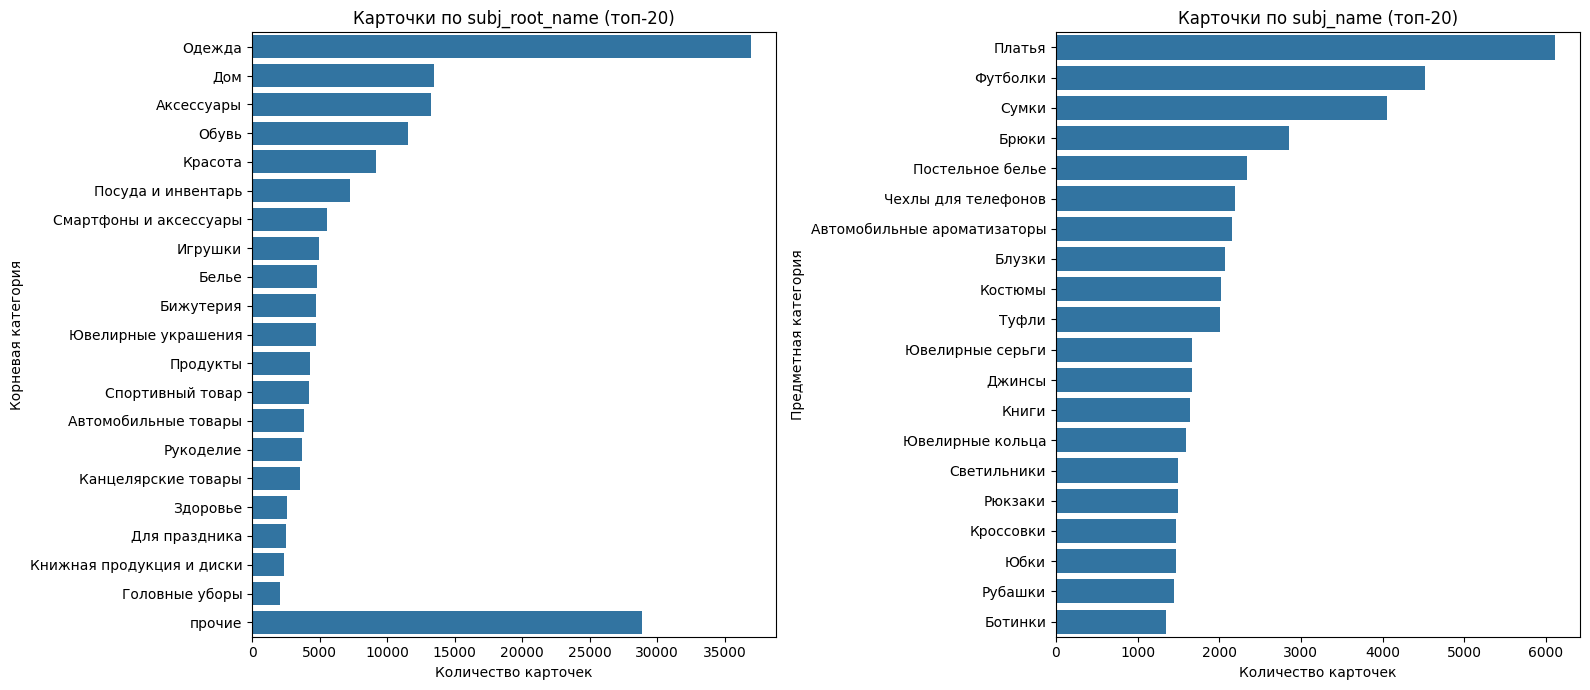

subj_name: 3234, with <= 2 cards: 820 (25.4%)
топ-20 предметных категорий покрывают 26.2% всех карточек


In [12]:
cards = df_raw.drop_duplicates("imt_id")

root = cards["subj_root_name"].value_counts()
root_top = pd.concat([root.head(20), pd.Series({"прочие": root.iloc[20:].sum()})])

subj = cards["subj_name"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(x=root_top.values, y=root_top.index, ax=axes[0])
axes[0].set(
    title="Карточки по subj_root_name (топ-20)",
    ylabel="Корневая категория",
    xlabel="Количество карточек",
)

sns.barplot(x=subj.head(20).values, y=subj.head(20).index, ax=axes[1])
axes[1].set(
    title="Карточки по subj_name (топ-20)",
    ylabel="Предметная категория",
    xlabel="Количество карточек",
)
plt.tight_layout()
plt.show()

print(
    f"subj_name: {len(subj)}, with <= 2 cards: {(subj <= 2).sum()} ({(subj <= 2).mean():.1%})"
)
print(
    f"топ-20 предметных категорий покрывают {subj.head(20).sum() / subj.sum():.1%} всех карточек"
)

In [13]:
q_root = (
    queries_train.merge(
        cards[["imt_id", "subj_root_name"]], left_on="item_id", right_on="imt_id"
    )
    .groupby("subj_root_name")["query_id"]
    .nunique()
)

root_stats = (
    cards.groupby("subj_root_name")
    .agg(cards=("imt_id", "size"), n_subj=("subj_name", "nunique"))
    .assign(
        cards_per_subj=lambda x: (x["cards"] / x["n_subj"]).round(1),
        train_queries=q_root,
    )
    .fillna({"train_queries": 0})
    .sort_values("cards", ascending=False)
)
root_stats.head(15)

,cards,n_subj,cards_per_subj,train_queries
subj_root_name,,,,
Одежда,36965,74,499.5,489.0
Дом,13482,141,95.6,0.0
Аксессуары,13230,73,181.2,0.0
Обувь,11524,30,384.1,211.0
Красота,9152,226,40.5,0.0
Посуда и инвентарь,7246,218,33.2,0.0
Смартфоны и аксессуары,5558,38,146.3,0.0
Игрушки,4944,100,49.4,0.0
Белье,4795,40,119.9,0.0


Всего 2 корневые категории покрывают всю обучающую выборку - дальнейшая работа будет именно с ними

In [14]:
roots = ["Одежда", "Обувь"]
sel = cards[cards["subj_root_name"].isin(roots)]
subj_sel = sel.groupby("subj_root_name")["subj_name"].value_counts()

rare = subj_sel[subj_sel <= 2]
print(f"редкие subj_name (<=2 карточек): {len(rare)} из {len(subj_sel)}")
display(rare)

display(subj_sel.groupby(level=0).head())

редкие subj_name (<=2 карточек): 5 из 104


subj_root_name  subj_name          
Одежда          Крестильные рубашки    2
                Брюки пижамные         1
                Дафлкоты               1
                Косухи                 1
                Крестильные платья     1
Name: count, dtype: int64

subj_root_name  subj_name
Обувь           Туфли        2013
                Кроссовки    1476
                Ботинки      1349
                Босоножки    1049
                Сапоги        874
Одежда          Платья       6113
                Футболки     4524
                Брюки        2858
                Блузки       2076
                Костюмы      2025
Name: count, dtype: int64

In [15]:
assert_items_preserved(sel, "Проверка выбранных категорий")
for split_name, q in [("train", queries_train), ("test", queries_test)]:
    linked = (
        q[["item_id"]]
        .drop_duplicates()
        .merge(
            cards[["imt_id", "subj_root_name"]],
            left_on="item_id",
            right_on="imt_id",
            how="left",
            validate="one_to_one",
        )
    )
    assert linked["subj_root_name"].notna().all()
    assert linked["subj_root_name"].isin(roots).all(), split_name
    print(split_name, linked["subj_root_name"].value_counts().to_dict())

Проверка выбранных категорий: все 2580 необходимых товаров сохранены
train {'Одежда': 1689, 'Обувь': 596}
test {'Одежда': 1246, 'Обувь': 426}


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Таблица `root_stats` с колонкой `train_queries` — отличная идея: сразу видно и объём категорий, и где лежит разметка. Выбор «Одежды» и «Обуви» подкреплён цифрой, а не общими соображениями, плюс отдельно проверены редкие `subj_name`.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Проверка сделана только по `queries_train`, а в выводе сказано про всю разметку. Добавь в эту проверку `queries_test` и поставь `assert`, что после фильтрации по `roots` не потерялся ни один размеченный `item_id` из обеих выборок. Если test-товар случайно окажется в другой категории, это всплывёт только в самом конце, на финальном прогоне, — а там исправлять уже поздно.
</div>

<div class="alert alert-info">
Поправил
</div>

#### Длина текстовых полей

In [16]:
main_text_fields = ["imt_name", "description"]
for field in main_text_fields:
    symbols = sel[field].astype(str).str.len()
    words = sel[field].astype(str).str.split().str.len()

    print(
        f"{field}:\nсимволов: {symbols.describe().round(1).to_dict()}\n"
        f"слов: {words.describe().round(1).to_dict()}\n"
    )

imt_name:
символов: {'count': 48489.0, 'mean': 13.9, 'std': 15.2, 'min': 0.0, '25%': 6.0, '50%': 8.0, '75%': 15.0, 'max': 100.0}
слов: {'count': 48489.0, 'mean': 1.9, 'std': 1.9, 'min': 0.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 19.0}

description:
символов: {'count': 48489.0, 'mean': 154.6, 'std': 335.8, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 195.0, 'max': 5000.0}
слов: {'count': 48489.0, 'mean': 21.1, 'std': 45.1, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 26.0, 'max': 704.0}



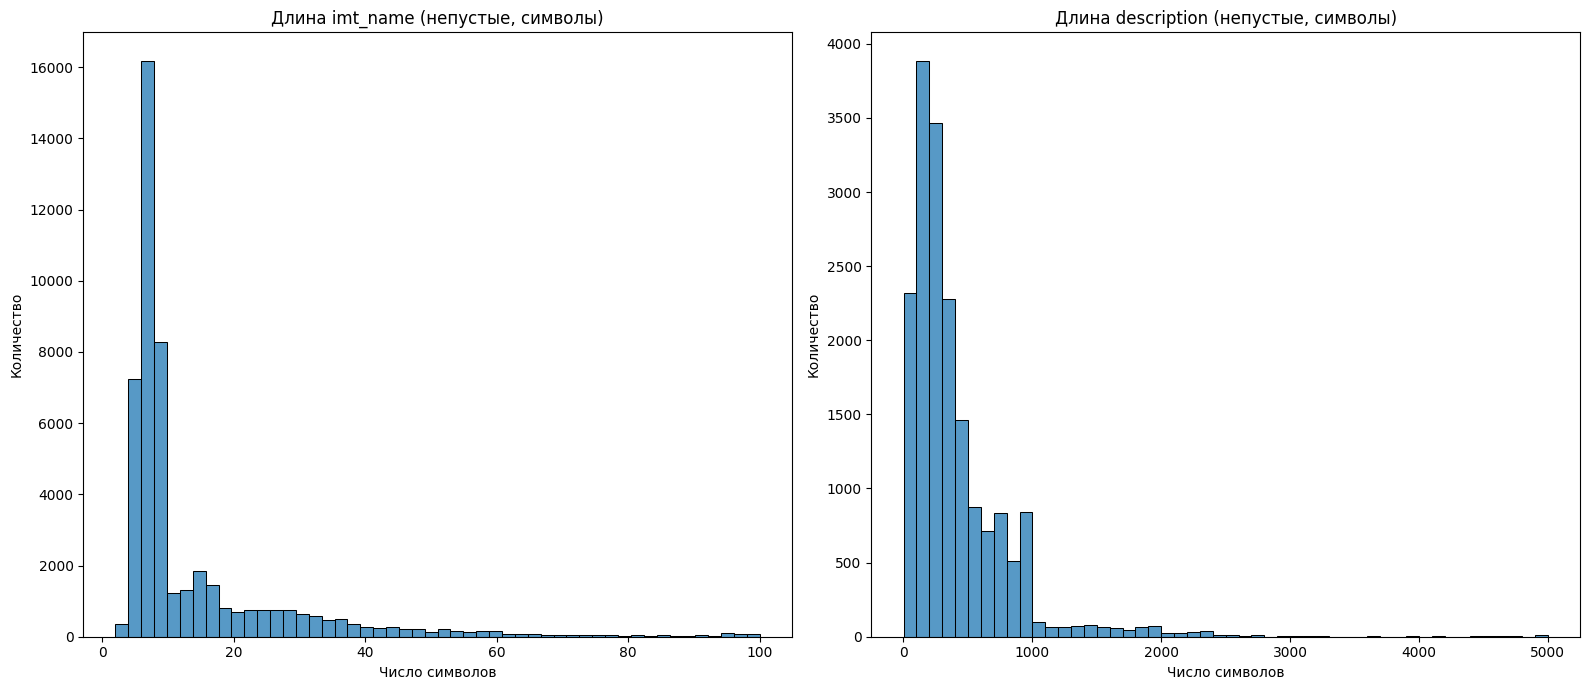

In [17]:
name = sel["imt_name"].str.strip()
name_lens = name[name != ""].str.len()

desc = sel["description"].str.strip()
desc_lens = desc[desc != ""].str.len()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.histplot(x=name_lens, bins=50, ax=axes[0])
axes[0].set(
    title="Длина imt_name (непустые, символы)",
    ylabel="Количество",
    xlabel="Число символов",
)

sns.histplot(x=desc_lens, bins=50, ax=axes[1])
axes[1].set(
    title="Длина description (непустые, символы)",
    ylabel="Количество",
    xlabel="Число символов",
)
plt.tight_layout()
plt.show()

In [18]:
desc_len = sel["description"].fillna("").str.len()
print(f"description > 2000 символов: {(desc_len > 2000).mean():.2%}")
print(
    f"description максимум (5000): {(desc_len == 5000).sum()}, imt_name максимум (100): {(sel['imt_name'].str.len() == 100).sum()}"
)

description > 2000 символов: 0.44%
description максимум (5000): 17, imt_name максимум (100): 44


По распределениям длины названий и описаний основная проблема - недостаток информации в карточках, поэтому в `product_text` добавляем предметную категорию и бренд. Длины в символах не позволяют определить долю текстов, обрезаемых энкодером: её проверяем токенизатором выбранной модели после сборки `product_text`. До этой проверки делать вывод о необходимости большего контекстного окна нельзя.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Длины полей разобраны подробно: и в символах, и в словах, распределения построены только по непустым значениям (иначе гистограмма описаний «утонула» бы в нулях), найдены значения 5000 и 100 — следы обрезки при выгрузке. Вывод «основная проблема — бедность текста, а не его длина» очень точный и дальше напрямую влияет на шаблон `product_text`.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Вывод про лимит в 512 токенов сделан по символам, а модель считает токены. Для русского текста у токенизаторов multilingual-моделей один токен — это примерно 3–4 символа, поэтому 2000 символов уже близко к лимиту. Предлагаю проверить напрямую: прогнать `emb_model.tokenizer` по `product_text` и посчитать долю текстов длиннее 512 токенов. Тогда утверждение «модель с большим окном не нужна» станет измеримым.
</div>

<div class="alert alert-info">
Решил чуть скорректировать комментарий
</div>

In [19]:
sample = sel[sel["description"].fillna("").str.strip() != ""].sample(
    25, random_state=RANDOM_STATE
)
for _, r in sample.iterrows():
    print(f"[{r.subj_name}] {r.imt_name} | {r.brand_name}")
    print(r.description[:500], "\n" + "-" * 80)

[Туфли] Туфли | S tell A
Свадебно-праздничные светлые туфли. Цвет бежевый. Высота каблука 11см. Закрытая платформа. Шпилька. Вставки из прозрачно-сетчатого текстиля. 
--------------------------------------------------------------------------------
[Юбки] Юбка | Mone
Юбка для школы из костюмной ткани  
--------------------------------------------------------------------------------
[Футболки] Футболка женская/для девочки | ILTANI
Хлопковая базовая футболка прямого кроя просто необходима девушкам, которые ценят стиль и комфорт. Актуальный полуприлегающий крой футболки гарантирует хорошую посадку по фигуре, создавая красивый силуэт. Неглубокий широкий округлый вырез придает простой модели ноты женственности. Благодаря минималистичному дизайну и базовому цвету идеально подойдет для капсульного гардероба, сочетается с вещами различных стилей, шортами 12777773, джинсами 12372888, леггинсами 9622408 или юбкой. Можно дополнить  
-----------------------------------------------------------------

In [20]:
desc = sel["description"].fillna("")
checks = {
    "html_tags": desc.str.contains(r"<[^>]+>"),
    "html_entities": desc.str.contains(r"&[a-z]+;|&#\d+;"),
    "urls": desc.str.contains(r"https?://|www\."),
    "vendor_code_in_name": sel.apply(
        lambda r: bool(r.vendor_code) and str(r.vendor_code) in str(r.imt_name), axis=1
    ),
}
print(pd.DataFrame(checks).mean().map("{:.2%}".format))

dup_desc = desc[desc != ""].value_counts()
print(
    f"Переиспользуемые descriptions >=5 карточек: {(dup_desc >= 5).sum()}, затронутые карточки: {dup_desc[dup_desc >= 5].sum()}"
)

html_tags              0.01%
html_entities          0.00%
urls                   0.00%
vendor_code_in_name    0.13%
dtype: object
Переиспользуемые descriptions >=5 карточек: 311, затронутые карточки: 3437


По цифрам HTML, сущности и URL практически отсутствуют, vendor_code в названии всего 0,13%, что довольно мало, поэтому удалять артикул из названий тоже не приоритетно, хотя и очистка контента от лишних html тегов как при обучении, так и при самом поиске, будет полезно. Хорошей находкой является шаблонные описания - 3437 карточек (~7% каталога) делят 311 одинаковых текстов, они делают разные товары похожими друг на друга, и поиск будет путать их между собой.

In [21]:
top = dup_desc[dup_desc >= 5].head(10).index
display(
    sel[desc.isin(top)]
    .groupby("description")
    .agg(
        cards=("imt_id", "size"),
        n_subj=("subj_name", "nunique"),
        n_brand=("brand_name", "nunique"),
    )
    .sort_values("cards", ascending=False)
)

,cards,n_subj,n_brand
description,,,
"Не спешите писать негативный отзыв при следующих ситуациях, независящих от нас: 1. Доставка задержалась или качество обслуживания в пункте выдачи не оправдало Ваших ожиданий. В данном случае напишите в техподдержку для оперативного решения. 2. Товар пришел поврежденным. Вы вправе отказаться от покупки и/или оформить возврат по браку. Товар спишут и утилизируют за наши средства, несмотря на вину доставщика/курьера, а Вам вернут денежные средства. 3. Пришел абсолютно другой товар. Пересортица товаров может происходить на складе. К сожалению, мы никак не можем повлиять на работу отдельных сотрудников марткеплейса, как бы этого не хотели. В данном случае необходимо оформить возврат, написать в техподдержку. С уважением, Ваш kari.",152,9,9
"Легкая и практичная Российская одежда бренда ""Линум"" как правило из льна и шерсти, плотная, качественная ткань, выпущенная ограниченной партией. Одна, две вещи на размер. Подчеркивующаяя принадлежность к Русскому стилю. Вся серия, -набрать Валберис поиск : Линум.",113,12,1
"Одежда ESPORT отличается лекгостью тканиЮ удобной ноской и приятная телу. Швы аккуратные, яркие цвета, упругая и втоже время тянеться до нужной посадки.",103,5,1
Гарантийный срок товара 30 дней.,100,15,1
"Мужская классическая рубашка. Сделано в России. Произведено специально для трех наших брендов: Broaden, Your Dream и Gioia di Mamma. Весь перечень производимой нами продукции Вы можете посмотреть на сайте Вайлдберриз. Просто напечатайте интересующий Вас бренд в поисковой строке сайта.",55,1,1
"Бандажное платье, моделирующее фигуру,с его помощью можно подтянуть,убрать лишние сантиметры,моделируя фигуру. Материал,корректирующий фасон,отработанные универсальные лекала скрывают недостатки,подчёркивая достоинства и женственность фигуры. Платье обтягивающее,приталенное,моделирующее,поэтому необходимо после того, как вы его одели,проверить,не перекрутили ли вы его при примерке,на месте ли боковые швы,необходимо расправить и потянуть его вниз,посадить грудь,особенно эффектно платье будет смотреться с пушапом. Стирка в стиральной машине на 30 градусах на бережном режиме или вручную. Длина платья меняется,когда садится по фигуре,поэтому прикладывать к себе сантиметр и пытаться понять,как оно сядет по длине сложно,на самом деле оно сядет по фигуре и будет от 3 до 7 см длиннее.",54,1,1
"Развитие ног ребенка - это важный элемент в их росте. В этот период, до и в самом начале ходьбы, важно, что дети носят обувь, адаптированную к их растущей ножке.12 принципов при производстве детской обуви ""BOPY"":1)Обувь, предназначенная исключительно для самых маленьких в размерах от 16 до 34.2)Гибкость обуви, так как ребенок живет в состоянии ""между ползать и стоять"".3)Усиленный подносок.4)Усиленная пятка ""задник"".5)Оптимальная подошва, не слишком толстая, чтобы оставаться гибкой.6)Обязателен маленький каблук.7)Противоскользящий состав подошвы.8)Кожаный верх обуви, обеспечивает комфорт, гибкость и позволяет ноге ""дышать"".9)Подкладка и стелька ,которые также могут ""дышать"".10)Арочные анатомические стельки.11)Мягкий валик в области лодыжки или наполнитель между верхом и подкладкой.12)Родители должны иметь возможность легко и быстро надеть/снять обувь с ребенка, что обеспечивается формой обуви и наличием продуманных крепежных элементов. И конечно дизайн, и качество исполнения обуви.",51,5,1
Данная модель обуви Эмальто маломерит на один размер. Обращайте внимание при заказе на таблицу размеров!,46,2,1
Специально для маленьких модниц наши дизайнеры разработали эксклюзивную коллекцию стильных детских футболок!,41,1,1


Часть из них - служебные тексты, не связанные с товаром (про отзывы, гарантию, бренд), поэтому описания, повторяющиеся у ≥5 карточек разных предметных категорий, будем считать пустыми, а шаблоны внутри одной категории оставим, так как они описывают сам тип товара.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Это один из самых сильных фрагментов работы. Ручной просмотр карточек не формальный: из него выросли конкретные проверки (HTML, сущности, URL, артикул в названии), а главное — находка с **шаблонными описаниями**. Тексты вроде «Не спешите писать негативный отзыв…» на 152 карточках из 9 категорий действительно сделали бы разные товары похожими друг на друга для эмбеддинга. Правило «повторяется у ≥5 карточек **разных** предметных категорий → считаем пустым, а внутри одной категории оставляем» — продуманное и аккуратное: служебный текст выкидывается, описание типа товара сохраняется.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Пара опечаток в выводах («не приоритено», «находной») — мелочь, но выводы в итоге читает заказчик, поэтому перед сдачей стоит пробежаться по тексту ещё раз.
</div>

<div class="alert alert-info">
Поправил
</div>

#### Формирование текста товара для эмбеддинга

In [22]:
name = sel["imt_name"].fillna("").str.lower()
subj = sel["subj_name"].fillna("").str.lower()
queries = queries_train.drop_duplicates("query_id")["query_text"].str.lower()
print(
    f"Предметных категорий в названии: {pd.Series([s in n for s, n in zip(subj, name)]).mean():.1%}"
)

Предметных категорий в названии: 40.4%


In [23]:
colors = sel["nm_colors_names"].fillna("").str.lower().str.split(r",\s*")
color_in_name = [any(c and c in n for c in cs) for cs, n in zip(colors, name)]
print(f"Цвет в названии: {pd.Series(color_in_name).mean():.1%}")

Цвет в названии: 0.6%


In [24]:
all_colors = {c for cs in colors for c in cs if len(c) > 3}
print(
    f"Среднее число запросов с указанием цвета: {queries.map(lambda q: any(c in q for c in all_colors)).mean():.1%}"
)

brands = {b for b in sel["brand_name"].dropna().str.lower() if len(b) > 3}
brand_re = {b: re.compile(rf"\b{re.escape(b)}\b") for b in brands}
hits = queries.map(lambda q: [b for b, r in brand_re.items() if r.search(q)])
print(f"Доля запросов с брендом: {(hits.str.len() > 0).mean():.1%}")
query_brand = (
    pd.DataFrame({"query": queries, "brand": hits})
    .explode("brand")
    .dropna(subset=["brand"])
    .reset_index(drop=True)
)
display(query_brand.head(20))

Среднее число запросов с указанием цвета: 3.3%
Доля запросов с брендом: 31.0%


,query,brand
0,лонгсливы love2wait,love2wait
1,джемперы stilla,stilla
2,кардиганы alcott,alcott
3,угги из овчины monqi,monqi
4,туники uniostar,uniostar
5,полусапожки loriblu,loriblu
6,ботинки baldinini,baldinini
7,пуховики acasta,acasta
8,худи adidas,adidas
9,пуловеры red soul,red soul


In [25]:
brand_check = queries_train.query("relevance == 3").merge(
    df_assessed[["imt_id", "brand_name"]],
    left_on="item_id",
    right_on="imt_id",
    how="left",
)

brand_check["brand_match"] = [
    bool(brand) and bool(re.search(rf"(?<!\w){re.escape(brand)}(?!\w)", query))
    for query, brand in zip(
        brand_check["query_text"].str.lower(),
        brand_check["brand_name"].fillna("").str.lower().str.strip(),
    )
]

is_brand = (
    brand_check.groupby("query_id")["brand_match"]
    .any()
    .reindex(queries_train["query_id"].unique(), fill_value=False)
)

print(f"Запросы с брендом товара с relevance = 3: {is_brand.mean():.1%}")

Запросы с брендом товара с relevance = 3: 31.4%


In [26]:
no_desc = (sel["description"].fillna("").str.strip() == "").mean()
print(f"Карточек без описания в Одежде и Обуви: {no_desc:.1%}")

Карточек без описания в Одежде и Обуви: 62.7%


Шаблон `product_text`: `imt_name . subj_name . description . brand_name`. Предметная категория дополняет короткое название, описание содержит характеристики товара, бренд нужен для точных запросов. Первоначальная доля 31% относится к совпадению с любым брендом из каталога. 31.4% - уточнённая доля запросов, содержащих бренд товара с `relevance = 3`. Цвет пока не включаем в общий текст: по исходному анализу он встречается примерно в 3,3% запросов.

Вывод: индекс строим по imt_id (разметка ссылается на карточки, на одну карточку приходится в среднем 1,15 артикула), дубли убираем, оставляя вариант с самым длинным описанием. Все 700 train-запросов относятся к "Одежде" и "Обуви", поэтому MVP строим на них. Тексты короткие (название обычно одно слово), у 62.7% карточек нет описания, у ~7% оно шаблонное, поэтому в product_text собираем `imt_name . subj_name . description . brand_name`: бренд упоминают 31.4% запросов, а цвет только 3%, его не включаем. В разметке почти все оценки равны 1, нулей нет, это важно для выбора порога.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Шаблон `product_text` обоснован полностью на данных, и это именно то, что ожидается в проекте: категория есть только в 40% названий → `subj_name` обязателен; цвет почти не встречается ни в названиях, ни в запросах → не включаем; бренд упоминается в 31% запросов → включаем. Мне нравится, что ты не побоялся(-ась) принять решение по бренду, которое расходится с «очевидным» вариантом (бренд часто выносят в фильтр), и подкрепил(а) его цифрой. Итоговый вывод недели 1 — компактный и полный, по нему можно восстановить все решения.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Формулировка «31% train-запросов называют бренд **релевантного товара**» сейчас сильнее, чем то, что проверено в коде: проверялось, что в запросе встречается какой-то бренд из каталога, а не бренд товара с высокой оценкой. Плюс поиск по словарю брендов может давать ложные срабатывания на коротких или «словарных» брендах. Чтобы утверждение стало точным, сравни найденный бренд с `brand_name` товара с `relevance = 3` для этого запроса — заодно получишь честную долю «брендовых» запросов, которая очень пригодится на неделе 3.
</div>

<div class="alert alert-info">
Поправил
</div>

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [27]:
TEMPLATE_FIELDS = ["imt_name", "subj_name", "description", "brand_name"]

In [28]:
categorized_df = df_raw.loc[df_raw["subj_root_name"].isin(["Одежда", "Обувь"])]
assert_items_preserved(categorized_df, "После фильтрации категорий")

После фильтрации категорий: все 2580 необходимых товаров сохранены


Для каждой карточки оставляем вариант с самым длинным описанием, при равной длине - с более длинным названием. Описание - основной источник смысла для поиска, а у 12% карточек с несколькими артикулами описания вариантов различаются, поэтому случайный выбор мог бы оставить пустое или урезанное описание.

In [29]:
def dedup_by_imt(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.assign(
            _desc_len=df["description"].fillna("").str.strip().str.len(),
            _name_len=df["imt_name"].fillna("").str.strip().str.len(),
        )
        .sort_values(["_desc_len", "_name_len"], ascending=False, kind="stable")
        .drop_duplicates("imt_id", keep="first")
        .drop(columns=["_desc_len", "_name_len"])
        .reset_index(drop=True)
    )


catalog_df = dedup_by_imt(categorized_df)

print(f"Число строк после категоризации: {len(categorized_df)}")
print(f"Число карточек после дедупликации: {len(catalog_df)}")

assert catalog_df["imt_id"].is_unique
assert_items_preserved(catalog_df, "После дедупликации")

Число строк после категоризации: 56503
Число карточек после дедупликации: 48489
После дедупликации: все 2580 необходимых товаров сохранены


In [30]:
has_name = catalog_df["imt_name"].fillna("").str.strip() != ""
has_desc = catalog_df["description"].fillna("").str.strip() != ""

filtered_df = catalog_df[has_name | has_desc].reset_index(drop=True)
print(
    f"До фильтрации: {len(catalog_df)}, после фильтрации: {len(filtered_df)}, удалено: {len(catalog_df) - len(filtered_df)}"
)
assert_items_preserved(filtered_df, "После удаления пустых карточек")

До фильтрации: 48489, после фильтрации: 48376, удалено: 113
После удаления пустых карточек: все 2580 необходимых товаров сохранены


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решения недели 1 реализованы последовательно: фильтр по категориям, дедупликация с явным и обоснованным правилом (самое длинное описание, при равенстве — самое длинное название), отсев только тех карточек, где пусты **одновременно** название и описание. Товары без описания сохранены — это правильно, у них остаются название, категория и бренд. `assert` на уникальность `imt_id` — хорошая привычка.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Добавь после каждого шага подготовки (фильтр, дедупликация, отсев пустых) проверку, что размеченные товары из train и test никуда не делись, например `assert labeled_ids <= set(filtered_df.imt_id)`. Сейчас это верно, но если на неделе 3 ты поменяешь правило очистки, такая проверка сразу скажет, что что-то сломалось.
</div>

<div class="alert alert-info">
Поправил
</div>

In [31]:
TAG_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MD_RE = re.compile(r"\*{1,}|_{2,}")
ARTICLE_RE = re.compile(r"\b\d{6,}\b")
SPECIAL_RE = re.compile(r"[^\w\s.,%\-/]")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    text = html.unescape(text)
    text = TAG_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = MD_RE.sub(" ", text)
    text = ARTICLE_RE.sub(" ", text)
    text = SPECIAL_RE.sub(" ", text)
    text = SPACE_RE.sub(" ", text)
    return text.strip().lower()


clean_df = filtered_df.copy()
for col in TEMPLATE_FIELDS:
    clean_df[col] = clean_df[col].fillna("").map(clean_text)

In [32]:
desc_stats = (
    clean_df[clean_df["description"] != ""]
    .groupby("description")
    .agg(n=("imt_id", "size"), n_subj=("subj_name", "nunique"))
)
template_desc = desc_stats[(desc_stats["n"] >= 5) & (desc_stats["n_subj"] > 1)].index
clean_df.loc[clean_df["description"].isin(template_desc), "description"] = ""
print(f"Удалено шаблонных текстовых описаний: {len(template_desc)}")

Удалено шаблонных текстовых описаний: 48


In [33]:
SEP = " . "


def build_product_text(row: pd.Series) -> str:
    parts = []
    for field in TEMPLATE_FIELDS:
        value = row[field]
        if value:
            parts.append(value)
    return SEP.join(parts)


products_df = clean_df.copy()
products_df["product_text"] = products_df.apply(build_product_text, axis=1)
eval_df = products_df[products_df["imt_id"].isin(df_assessed["imt_id"])].reset_index(
    drop=True
)

assert (eval_df["product_text"] != "").all()
display(eval_df[["imt_id", "product_text"]].sample(10, random_state=RANDOM_STATE))
print(f"Полный каталог: {len(products_df):,} карточек")
print(f"Каталог оценки: {len(eval_df):,} из {len(assessor_ids):,} карточек пула")

,imt_id,product_text
184,10109603,платье льняное оверсайз . платья . стильное пл...
1018,10038252,"брюки женские ariel ,большие размеры,высокая п..."
2909,10101802,футболка . футболки . футболка свободного покр...
2704,10165922,"платье . платья . легкое , элегантное платье. ..."
602,10103179,сарафан женский . сарафаны . глубокий вырез го...
3881,10118902,кигуруми скелет . кигуруми . rumiland
1235,10107003,брюки женские классические . брюки . модель 30...
438,10025101,кроссовки . кроссовки . очень легкие невесомые...
2338,10002534,туника . туники . яркая туника с оригинальным ...
109,10130640,ветровки . ветровки . модный анорак ветровка м...


Полный каталог: 48,376 карточек
Каталог оценки: 4,256 из 4,256 карточек пула


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очистка текста опирается на конкретные находки EDA, а не на абстрактный «мусор»: `ARTICLE_RE` убирает номера артикулов вида «шортами 12777773», которые ты увидел(а) при ручном просмотре, плюс шаблонные описания обнуляются по правилу, сформулированному выше. `html.unescape` перед удалением тегов — грамотный порядок. `product_text` собран правильно: явный разделитель, пустые поля пропускаются, висящих разделителей нет, а `assert` гарантирует отсутствие пустых текстов. Хорошо и то, что запрос проходит ту же `clean_text`, что и товары.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Каталог оценки `eval_df` собран, но его размер нигде не выведен и не сверен с пулом асессоров. Выведи `len(eval_df)` и проверь, что все `imt_id` из `wb_products_dedup.parquet` нашлись в твоём подготовленном каталоге (должно получиться 4256 из 4256) — иначе часть пула могла молча потеряться на этапе фильтрации.
</div>

<div class="alert alert-info">
Поправил
</div>

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Этот раздел пропущен: в коде сразу используется каталог, ограниченный пулом асессоров, но не показано, **почему** так нужно делать. Это обязательная часть недели 2, и именно она объясняет, как интерпретировать все дальнейшие метрики. Что нужно сделать:

1. Посчитать метрику (например, NDCG@10 лексическим поиском на 100 запросах) по **всему** отфильтрованному каталогу `products_df`, а не по пулу.
2. Вывести топ-10 для одного запроса и отметить, какие товары есть в разметке, а каких нет. Сформулировать, в чём проблема.
3. Пересчитать ту же метрику на `eval_df` и сравнить.

Инфраструктура у тебя для этого уже полностью готова — `make_lexical_search(products_df)` и функция `evaluate` (её можно запустить на подвыборке из 100 запросов). Так что работы здесь немного, а вывод получится очень показательным.
</div>

<div class="alert alert-info" style="border:2px solid #3178b8; padding:14px">
Сравнение полного каталога и пула асессоров реализовано ниже, сразу после определения поисковых моделей и evaluate. Оба варианта используют одинаковые параметры TF-IDF, но векторизаторы обучаются отдельно на соответствующих каталогах. Это сохраняет порядок зависимостей при запуске тетради сверху вниз.
</div>

### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [34]:
def make_search(df, item_vectors, encode_query):
    knn = NearestNeighbors(metric="cosine", algorithm="brute").fit(item_vectors)
    meta = df[["imt_id", "imt_name", "subj_name"]].reset_index(drop=True)

    def search(query: str, top_k: int = 10) -> pd.DataFrame:
        dist, idx = knn.kneighbors(encode_query(clean_text(query)), n_neighbors=top_k)
        return meta.iloc[idx[0]].assign(score=1 - dist[0]).reset_index(drop=True)

    return search


Реализуйте лексический baseline на TF-IDF:

In [35]:
def make_lexical_search(df, min_df=2):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, sublinear_tf=True)
    tfidf = vectorizer.fit_transform(df["product_text"])
    return make_search(df, tfidf, lambda q: vectorizer.transform([q]))


search_lexical_1df = make_lexical_search(eval_df, min_df=1)
display(search_lexical_1df("кроссовки для бега (min_df=1)", 5))

search_lexical_2df = make_lexical_search(eval_df, min_df=2)
display(search_lexical_2df("кроссовки для бега (min_df=2)", 5))

,imt_id,imt_name,subj_name,score
0,10034136,кроссовки,кроссовки,0.162151
1,10165379,кроссовки,кроссовки,0.154703
2,10158654,кроссовки женские,кроссовки,0.135576
3,1000379,кроссовки,кроссовки,0.128791
4,10106706,кроссовки adrenalite 2.1,кроссовки,0.127908


,imt_id,imt_name,subj_name,score
0,10076338,кроссовки abyss,кроссовки,0.326655
1,10034136,кроссовки,кроссовки,0.206431
2,10007080,кроссовки falcon w vappnk/sigorg/legblu,кроссовки,0.202465
3,10153575,кроссовки killington f/l sock fitox,полуботинки,0.201287
4,10165379,кроссовки,кроссовки,0.191682


Реализуйте семантический поиск:

In [36]:
EMB_MODEL_NAME = "intfloat/multilingual-e5-small"
EMB_PATH = Path("artifacts/emb_e5_small.npy")
emb_model = SentenceTransformer(EMB_MODEL_NAME, device=device)


def make_semantic_search(df: pd.DataFrame, emb_path: Path):
    text_hash = hashlib.md5("\n".join(df["product_text"]).encode()).hexdigest()[:12]

    emb_path = emb_path.with_name(f"{emb_path.stem}_{text_hash}{emb_path.suffix}")
    if emb_path.exists():
        emb = np.load(emb_path)
    else:
        texts = ("passage: " + df["product_text"]).tolist()
        emb = emb_model.encode(
            texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True
        )
        emb_path.parent.mkdir(exist_ok=True)
        np.save(emb_path, emb)

    assert emb.shape[0] == len(df), "Размер кеша не совпадает с каталогом"
    return make_search(
        df, emb, lambda q: emb_model.encode(["query: " + q], normalize_embeddings=True)
    )


search_semantic = make_semantic_search(eval_df, EMB_PATH)
display(search_semantic("кроссовки для бега", 5))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/67 [00:00<?, ?it/s]

,imt_id,imt_name,subj_name,score
0,10026767,speed 2 w grey peach,кроссовки,0.897694
1,10106850,кроссовки puma taper,кроссовки,0.893169
2,10106851,кроссовки puma taper sl,кроссовки,0.892720
3,10007065,кроссовки activeplay minnie,кроссовки,0.890295
4,10094321,кроссовки alphacross blast,кроссовки,0.886634


In [ ]:
encoded = emb_model.tokenizer(
    products_df["product_text"].tolist(),
    truncation=False,
    padding=False,
    add_special_tokens=True,
)
token_lengths = pd.Series([len(ids) for ids in encoded["input_ids"]])
print(
    f"Текстов длиннее 512 токенов: "
    f"{(token_lengths > 512).mean():.2%} "
    f"({(token_lengths > 512).sum()} из {len(token_lengths)})"
)


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Архитектура поиска мне очень понравилась. Вместо двух похожих функций ты сделал(а) одну фабрику `make_search`, которая принимает матрицу векторов и функцию кодирования запроса — и работает одинаково и для разреженной TF-IDF, и для плотных эмбеддингов. Это гарантирует одинаковый интерфейс и отлично подойдёт для гибридного поиска на неделе 3.

По семантике: выбор `multilingual-e5-small` удачный (русский язык, окно 512 токенов, работает быстро), и — что важно — ты правильно используешь префиксы `query:` / `passage:`, без которых e5 заметно теряет в качестве. Эмбеддинги нормализованы, считаются батчами и кешируются на диск. TF-IDF с биграммами и `sublinear_tf` — разумная настройка baseline.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Две вещи, которые стоит учесть до экспериментов:

1. **Кеш эмбеддингов.** Сейчас файл загружается, если просто существует по пути. На неделе 3, как только ты поменяешь шаблон `product_text` или состав каталога, из кеша молча подтянутся старые векторы, и эксперимент покажет неверные числа. Добавь проверку `emb.shape[0] == len(df)` и включи в имя файла что-то, что меняется вместе с текстом (название шаблона или хеш от `product_text`).
2. **`min_df=2` на каталоге в 4256 карточек** выкидывает все слова, которые встречаются в одной карточке, — а это как раз редкие бренды, на которых, по твоей же гипотезе, лексический поиск должен быть сильнее. Хороший кандидат на отдельный эксперимент: `min_df=1` или обучение `TfidfVectorizer` на всём каталоге из 48 тыс. карточек (более устойчивые IDF) при поиске по пулу.
</div>

<div class="alert alert-info" style="border:2px solid #3178b8; padding:14px">
Поправил
</div>

Прогоните 3–5 запросов вручную и сравните выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [37]:
sample_q = queries_train.drop_duplicates("query_id").sample(
    5, random_state=RANDOM_STATE
)

for _, row in sample_q.iterrows():
    rel = queries_train.loc[queries_train["query_id"] == row.query_id].set_index(
        "item_id"
    )["relevance"]
    print(f"\n{row.query_text}")
    for name, search_fn in [
        ("lexical (min_df=1)", search_lexical_1df),
        ("lexical (min_df=2)", search_lexical_2df),
        ("semantic", search_semantic),
    ]:
        res = search_fn(row.query_text, 3)
        res["relevance"] = res["imt_id"].map(rel)
        print(f"- {name}")
        display(res)


топы cop copine
- lexical (min_df=1)


,imt_id,imt_name,subj_name,score,relevance
0,10022252,топ,топы,0.221327,3.0
1,10022262,платье,платья,0.200242,NaN
2,10022246,брюки,брюки,0.193187,NaN


- lexical (min_df=2)


,imt_id,imt_name,subj_name,score,relevance
0,10022252,топ,топы,0.319451,3.0
1,10022246,брюки,брюки,0.277057,NaN
2,10022245,брюки,брюки,0.254587,NaN


- semantic


...

,imt_id,imt_name,subj_name,score,relevance
0,10072453,сабо,сабо,0.182483,2
1,10072475,сабо,сабо,0.158885,2
2,101032,сабо,сабо,0.147985,1


- lexical (min_df=2)


,imt_id,imt_name,subj_name,score,relevance
0,10049777,тапочки махровые комфорт с открытым мысом,тапочки,0.230381,NaN
1,10072453,сабо,сабо,0.209706,2.0
2,10105641,сабо,туфли,0.199432,NaN


- semantic


,imt_id,imt_name,subj_name,score,relevance
0,10012359,сабо открытый мыс кожаные с перфорацией на пла...,сабо,0.896044,NaN
1,10072453,сабо,сабо,0.893182,2.0
2,10072475,сабо,сабо,0.887066,2.0


Подходы дополняют друг друга. Lexical сильнее на брендах и точных редких словах, semantic - на синонимах, морфологии и смысле. Отсюда гипотеза для гибридного поиска.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ручное сравнение сделано очень грамотно: рядом с каждым результатом выводится `relevance` из разметки, поэтому сразу видно не только «что нашлось», но и «правильно ли». Вывод опирается на увиденное: на «топы cop copine» и «худи mego as» лексика ставит товар с оценкой 3 на первое место, а семантика находит «зуавы» по смыслу там, где TF-IDF видит только «бриджи». Гипотеза о гибридном поиске выросла из конкретных примеров — так и нужно.
</div>

### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

Оценки распределены неравномерно: 84% - 1, 10% - 2, 6% - 3. Нулей нет, на каждый запрос приходится одна оценка 3. Порог бинаризации - 2: при пороге 1 все размеченные товары становятся релевантными, при пороге 3 остаётся единственная карточка на запрос. У всех запросов есть товар с relevance >= 2, но медиана - один такой товар на запрос, поэтому Precision@K ограничен сверху, а основными метриками считаем NDCG@K и MRR.

In [38]:
RELEVANCE_THRESHOLD = 2
K_VALUES = [1, 3, 5, 10]


def query_metrics(found_ids, rel_map, k, threshold):
    rels = [rel_map.get(i, 0) for i in found_ids[:k]]
    hits = [r >= threshold for r in rels]
    n_relevant = sum(r >= threshold for r in rel_map.values())

    dcg = sum((2**r - 1) / np.log2(pos + 2) for pos, r in enumerate(rels))
    ideal = sorted(rel_map.values(), reverse=True)[:k]
    idcg = sum((2**r - 1) / np.log2(pos + 2) for pos, r in enumerate(ideal))

    return {
        f"precision@{k}": sum(hits) / k,
        f"recall@{k}": sum(hits) / n_relevant if n_relevant else np.nan,
        f"hitrate@{k}": float(any(hits)),
        f"ndcg@{k}": dcg / idcg if idcg else np.nan,
    }


def reciprocal_rank(found_ids: list, rel_map: dict, threshold: int) -> float:
    for pos, item in enumerate(found_ids, start=1):
        if rel_map.get(item, 0) >= threshold:
            return 1 / pos
    return 0.0

In [39]:
golden = {
    qid: dict(zip(g["item_id"], g["relevance"]))
    for qid, g in queries_train.groupby("query_id")
}
query_texts = queries_train.drop_duplicates("query_id").set_index("query_id")[
    "query_text"
]


def evaluate(search_fn, queries_df, threshold=RELEVANCE_THRESHOLD, k_values=K_VALUES):
    depth = max(k_values)
    rows = []
    for qid, group in queries_df.groupby("query_id", sort=True):
        rel_map = dict(zip(group["item_id"], group["relevance"]))
        found = search_fn(group["query_text"].iloc[0], depth)["imt_id"].tolist()
        assert len(found) == len(set(found)), "В выдаче повторяются карточки"
        row = {"query_id": qid}
        for k in k_values:
            row.update(query_metrics(found, rel_map, k, threshold))
        has_relevant = any(r >= threshold for r in rel_map.values())
        row[f"mrr@{depth}"] = (
            reciprocal_rank(found[:depth], rel_map, threshold)
            if has_relevant
            else np.nan
        )
        rows.append(row)
    return pd.DataFrame(rows)


per_query = {
    name: evaluate(fn, queries_train)
    for name, fn in [
        ("lexical (min_df=1)", search_lexical_1df),
        ("lexical (min_df=2)", search_lexical_2df),
        ("semantic", search_semantic),
    ]
}
summary = pd.DataFrame(
    {name: df.drop(columns="query_id").mean() for name, df in per_query.items()}
).T
summary.insert(0, "threshold", RELEVANCE_THRESHOLD)
display(summary.round(3))

,threshold,precision@1,recall@1,hitrate@1,ndcg@1,precision@3,recall@3,hitrate@3,ndcg@3,precision@5,recall@5,hitrate@5,ndcg@5,precision@10,recall@10,hitrate@10,ndcg@10,mrr@10
lexical (min_df=1),2,0.214,0.145,0.214,0.255,0.149,0.261,0.346,0.345,0.129,0.355,0.466,0.394,0.100,0.489,0.617,0.454,0.318
lexical (min_df=2),2,0.123,0.080,0.123,0.194,0.110,0.186,0.271,0.297,0.102,0.270,0.370,0.350,0.088,0.421,0.553,0.427,0.233
semantic,2,0.523,0.337,0.523,0.440,0.350,0.553,0.743,0.537,0.270,0.648,0.816,0.557,0.174,0.757,0.887,0.557,0.648


In [40]:
sample_qids = queries_train["query_id"].drop_duplicates().sample(
    100, random_state=RANDOM_STATE
)
queries_100 = queries_train[
    queries_train["query_id"].isin(sample_qids)
]

search_full_lexical = make_lexical_search(products_df, min_df=2)
search_eval_lexical = make_lexical_search(eval_df, min_df=2)

full_metrics = evaluate(search_full_lexical, queries_100)
eval_metrics = evaluate(search_eval_lexical, queries_100)

comparison = pd.DataFrame({
    "full_catalog": full_metrics.drop(columns="query_id").mean(),
    "assessor_pool": eval_metrics.drop(columns="query_id").mean(),
})

display(comparison.loc[["ndcg@10", "mrr@10", "hitrate@10"]].round(3))

,full_catalog,assessor_pool
ndcg@10,0.086,0.465
mrr@10,0.091,0.285
hitrate@10,0.180,0.670


In [41]:
example = queries_100.iloc[0]
rel_map = queries_100[
    queries_100["query_id"] == example["query_id"]
].set_index("item_id")["relevance"]

top10 = search_full_lexical(example["query_text"], 10)
top10["relevance_for_query"] = top10["imt_id"].map(rel_map)
top10["is_labeled_for_query"] = top10["imt_id"].isin(rel_map.index)
top10["is_in_assessor_pool"] = top10["imt_id"].isin(
    set(df_assessed["imt_id"])
)

display(top10)

,imt_id,imt_name,subj_name,score,relevance_for_query,is_labeled_for_query,is_in_assessor_pool
0,1001100,лонгслив,лонгсливы,0.860103,NaN,False,False
1,1001102,лонгслив,лонгсливы,0.860103,NaN,False,False
2,1001104,лонгслив,лонгсливы,0.860103,NaN,False,False
3,1001103,лонгслив,лонгсливы,0.860103,NaN,False,False
4,1001099,лонгслив,лонгсливы,0.860103,NaN,False,False
5,1001085,лонгслив,лонгсливы,0.860103,NaN,False,False
6,1001060,лонгслив,лонгсливы,0.860103,NaN,False,False
7,1001061,лонгслив,лонгсливы,0.860103,NaN,False,False
8,1001058,лонгслив,лонгсливы,0.860103,NaN,False,False
9,1001059,лонгслив,лонгсливы,0.860103,NaN,False,False


In [42]:
metrics_by_brand = pd.concat({
    name: (
        metrics.set_index("query_id")
        .join(is_brand.rename("is_brand"))
        .groupby("is_brand").mean()
    )
    for name, metrics in per_query.items()
}, names=["method"])

display(metrics_by_brand.round(3))

precision@1  recall@1  hitrate@1  ndcg@1  \
method             is_brand                                             
lexical (min_df=1) False           0.154     0.086      0.154   0.208   
                   True            0.345     0.274      0.345   0.357   
lexical (min_df=2) False           0.083     0.041      0.083   0.167   
                   True            0.209     0.166      0.209   0.253   
semantic           False           0.510     0.291      0.510   0.407   
                   True            0.550     0.437      0.550   0.514   

                             precision@3  recall@3  hitrate@3  ndcg@3  \
method             is_brand                                             
lexical (min_df=1) False           0.115     0.159      0.265   0.287   
                   True            0.224     0.482      0.523   0.473   
lexical (min_df=2) False           0.083     0.106      0.208   0.255   
                   True            0.171     0.362      0.409   0.389   
semantic           False           0.365     0.500      0.754   0.505   
                   True            0.318     0.669      0.718   0.609   

                             precision@5  recall@5  hitrate@5  ndcg@5  \
method             is_brand                                             
lexical (min_df=1) False           0.105     0.220      0.362   0.330   
                   True            0.182     0.650      0.691   0.532   
lexical (min_df=2) False           0.082     0.164      0.288   0.304   
                   True            0.145     0.503      0.550   0.450   
semantic           False           0.295     0.604      0.831   0.531   
                   True            0.215     0.743      0.782   0.615   

                             precision@10  recall@10  hitrate@10  ndcg@10  \
method             is_brand                                                 
lexical (min_df=1) False            0.092      0.340       0.512    0.398   
                   True             0.119      0.814       0.845    0.576   
lexical (min_df=2) False            0.081      0.296       0.477    0.383   
                   True             0.103      0.694       0.718    0.523   
semantic           False            0.198      0.727       0.904    0.537   
                   True             0.120      0.822       0.850    0.599   

                             mrr@10  
method             is_brand          
lexical (min_df=1) False      0.244  
                   True       0.480  
lexical (min_df=2) False      0.179  
                   True       0.351  
semantic           False      0.648  
                   True       0.648

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Метрики реализованы корректно и компактно: порог бинаризации вынесен в параметр, NDCG считается по полной шкале с `gain = 2^rel - 1`, IDCG — по идеальному ранжированию из разметки, неразмеченные товары трактуются как `0` через `rel_map.get(i, 0)`. Деление `precision` на `k` (а не на число найденных) — правильный выбор. Обоснование порога `2` в Markdown — отличное: показано, что при пороге 1 релевантно всё, а при пороге 3 остаётся одна карточка на запрос, и сделан вывод, почему главными метриками становятся NDCG и MRR.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Функция `evaluate` берёт `golden` и `query_texts` из глобальных переменных, построенных по `queries_train`. На неделе 3 понадобится оценивать ту же модель на val-части и на test — передавай набор разметки аргументом (например, `evaluate(search_fn, queries_df, ...)`), чтобы одна и та же функция работала для любой выборки без копирования кода. Ещё мелочь: MRR фактически считается по топ-10, так что честнее назвать его `mrr@10`.
</div>

<div class="alert alert-info" style="border:2px solid #3178b8; padding:14px">
Поправил
</div>

Вывод: На 100 одинаковых train-запросах TF-IDF на полном каталоге показал NDCG@10 = 0,086, MRR@10 = 0,091 и HitRate@10 = 0,180. На пуле асессоров эти метрики составили 0,465, 0,285 и 0,670. В показанном примере все товары из top-10 отсутствуют в разметке конкретного запроса, поэтому они учитываются как нерелевантные. Это занижает метрики и показывает ограниченность пулированной разметки. Поэтому дальнейшее сравнение моделей проводим на eval_df, а его результаты не переносим напрямую на весь каталог.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Хороший промежуточный итог: семантический поиск на e5-small уверенно обходит TF-IDF по всем метрикам, а следующие шаги (гибрид, лемматизация, модель посильнее) вытекают из проделанного анализа.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Сверь, пожалуйста, числа в выводе с таблицей выше — часть значений для TF-IDF не совпадает с тем, что посчитано в `summary`. В выводах для бизнеса такие расхождения сразу подрывают доверие ко всей работе.

И второе: утверждение «TF-IDF лучше ловит бренды» сейчас опирается только на пару примеров. У тебя уже есть разметка «брендовых» запросов из EDA — посчитай метрики обоих подходов отдельно для запросов с брендом и без. Если гипотеза подтвердится, получишь прямое количественное обоснование для гибридного поиска.
</div>

<div class="alert alert-info">
Поправил
</div>

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите минимум три эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — ваше предположение и его обоснование. Причины «хочу попробовать другую модель» недостаточно, нужны объяснения такого типа: «Модель с большим окном улучшит поиск товаров с длинными описаниями, потому что в EDA я видел, что X% описаний обрезаются по лимиту токенов».
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что это говорит о данных?

Придумывайте гипотезы, опираясь на ошибки, которые обнаружили на неделе 2. Если выбранная модель путает смежные категории, попробуйте проверить, решит ли проблему добавление данных из `subj_name` в общий текст карточки. Другой пример: если лексический поиск обходит семантический на точных названиях, а семантический выигрывает у лексического, когда дело доходит до неточных формулировок, — это повод попробовать реализовать гибридный поиск.

Направления для разработки гипотез:

- изменить шаблон `product_text`;
- попробовать другую модель эмбеддингов;
- дообучить модели;
- реализовать гибридный поиск с помощью взвешенной суммы скоров или реранкинга семантикой поверх лексического отбора;
- ввести лемматизацию и стоп-слова для TF-IDF;
- изменить параметры векторизации.

In [43]:
# Эксперимент 1
# Гипотеза:
# Что меняем:


# Ваш код

...

Ellipsis

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Раздел с экспериментами не выполнен, а это ключевая часть недели 3. Нужно минимум три эксперимента, каждый по схеме «гипотеза → одно изменение → метрики → вывод».

Перед экспериментами важно организовать валидацию: раздели `queries_train` на fit/val **по `query_id`** (например, 80/20 с фиксированным сидом). Все подборы — веса в гибриде, параметры TF-IDF, выбор модели — делаются по val, а `test` остаётся нетронутым до финального прогона.

Хорошая новость: гипотезы у тебя уже по сути сформулированы и обоснованы данными, их осталось проверить. Например:
- гибридный поиск (взвешенная сумма нормированных скоров TF-IDF и e5) — обоснование: лексика выигрывает на брендах, а их в запросах заметная доля;
- `min_df=1` / IDF по всему каталогу для TF-IDF — обоснование: редкие бренды сейчас выпадают из словаря;
- более крупная модель (`multilingual-e5-base` / `bge-m3`) или дообучение e5-small на fit-парах с `relevance ≥ 2`.

Твоя фабрика `make_search` позволяет собрать любой из этих вариантов в пару строк.
</div>

### 2. Финальный тест

Выборка `test` нужна для финальной проверки модели, когда конфигурация окончательно выбрана по результатам валидации. Каждый повторный прогон с подстройкой превращает `test` в ещё одну валидацию и обесценивает финальные показатели.

In [44]:
RUN_FINAL_TEST_EVAL = False  # Переведите в True, когда конфигурация финальная

# Ваш код


<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Финальный прогон на `test` не выполнен. После выбора лучшей конфигурации по val нужно один раз оценить её (и baseline для сравнения) на `queries_test` с тем же порогом и теми же K.
</div>

### 3. Трекинг экспериментов в MLflow

Каждая конфигурация — отдельный run с осмысленным именем (`semantic_bge_m3`, а не `run_7`).

Что логировать:
- Все параметры, известные до запуска, — метод, модель, шаблон текста, порог, размер каталога, сид.
- Метрики — все посчитанные значения.
- Артефакты — таблица метрик по запросам, сводная таблица, графики, копия данных, на которых проводилась проверка.

In [45]:
# Ваш код: подключение к MLflow из .env и логирование прогонов

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Трекинг в MLflow не реализован. Каждая конфигурация — отдельный run с осмысленным именем (`semantic_e5_small`, `hybrid_alpha_0.5` и т.п.). Логировать нужно параметры (метод, модель, шаблон текста, порог, размер каталога, сид), все метрики и артефакты — таблицу метрик по запросам, сводную таблицу, графики. Подключение бери из `.env` так же, как ты уже сделал(а) для S3.
</div>

### 4. Финальные выводы

**4.1. Сводная таблица.** Все подходы на одних данных, с одинаковыми порогом и K. Укажите лучшую конфигурацию и метрики, по которым был сделан вывод.

**4.2. Качественный анализ.** Числа показывают не всю картину. Возьмите запросы, где лучший подход всё ещё ошибается, и опишите характер ошибок.

**4.3. Ограничения оценки.** Перечислите ограничения модели и данных, на которых проводились эксперименты. Например:

- разметка синтетическая и пулированная;
- каталог оценки меньше реального;
- запросы сгенерированы, а не собраны от пользователей.

Этот раздел не ослабляет работу, а усиливает её: специалист, понимающий границы своего решения, вызывает больше доверия.

**4.4. Рекомендация бизнесу.** Скажите заказчику, внедрять ли ему векторный поиск или нет, в каком виде его лучше реализовывать, в каких сценариях он будет помогать, а где может ошибаться.

**4.5. Дальнейшие шаги.** Перечислите возможные действия, которые могли бы улучшить результат:

- использовать реальные логи запросов вместо синтетических;
- перейти на ANN-индекс при росте каталога;
- применить фильтры по атрибутам поверх векторного поиска.

Все возможные шаги обоснуйте.


*Ваши выводы:*


<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Финальные выводы (пп. 4.1–4.5) не заполнены: нужны сводная таблица всех подходов, качественный разбор ошибок лучшего подхода, ограничения оценки, рекомендация бизнесу и дальнейшие шаги. Многое для разделов 4.2 и 4.3 у тебя уже есть: наблюдения про синтетические запросы, пулированную разметку, отсутствие нулевых оценок и поведение моделей на брендах — их нужно только собрать вместе и дополнить результатами экспериментов.
</div>

<div style="border:solid Chocolate 2px; padding: 40px">

**Общий вывод по проекту ревьювера v1**:

Спасибо за проект! Первые две недели выполнены на очень высоком уровне: видно, что за каждым шагом стоит понимание, а не следование шаблону. Сейчас работа выполнена не до конца — нет части недели 2 и всей недели 3, — но фундамент для них у тебя отличный.

**Отмечу положительные моменты**:

1. EDA построен на доказательствах: уровень индекса подтверждён проверкой `imt_id` против `nm_id`, выбор категорий — таблицей с распределением запросов, а шаблон `product_text` — долями категорий, цветов и брендов в названиях и запросах.

2. Находка с шаблонными описаниями и продуманное правило их удаления (разные категории → служебный текст, одна категория → описание типа товара), а очистка текста опирается на то, что ты увидел(а) при ручном просмотре.

3. Чистая архитектура кода: единая фабрика `make_search` для лексического и семантического поиска, корректное использование префиксов e5, кеширование эмбеддингов, компактные и правильные метрики с параметром порога.

4. Сильное обоснование порога бинаризации и выбора основных метрик.

**На что стоит обратить внимание**:

1. Выполнить раздел «Каталог для поиска и оценки»: сравнить метрику на полном каталоге и на пуле асессоров и объяснить разницу.

2. Выполнить неделю 3: разбиение train на fit/val по `query_id`, минимум три эксперимента по схеме «гипотеза → одно изменение → результат → вывод», один финальный прогон на test, логирование в MLflow и финальные выводы с рекомендацией бизнесу.

3. Учесть небольшие замечания: проверки, что размеченные товары не теряются, кеш эмбеддингов, параметризация `evaluate` и сверка чисел в выводах.

**Удачи и жду твой проект на повторное ревью!**
</div>